# ***Εργασία 1 – Επιβλεπόμενη Μάθηση***

In [30]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler

#Μέρος 1_ Ερώτημα1
______________________________________________________________________________________________

# Φορτώνουμε το σύνολο δεδομένων σε DataFrame και εμφανίζουμε τις πρώτες γραμμές για έλεγχο.
df = pd.read_csv('diabetes.csv')
#display(df.head())

# Περιγραφή κάθε χαρακτηριστικού (μέση τιμή, τυπική απόκλιση, ελάχιστη, μέγιστη τιμή)
df.describe()



,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


**Περιγραφή μεταβλητών:**

1)*Pregnancies:* αναφέρεται στον συνολικό αριθμό των εγκυμοσύνων που έχει μια ασθενής.

2)*Glycose:* αναφέρεται στη συγκέντρωση της γλυκόζης στο αίμα.

3)*BloodPressure:* δείχνει την τιμή της αρτηριακής πίεσης του ασθενή.

4)*SickThickness:* μετρά το πάχος της πτυχής του δέρματος στον τρικέφαλο για την εκτίμηση του λίπους.

5)*Insulin:* αφορά το επίπεδο τη ινσουλίνης στο αίμα.

6)*DiabetesPedigreeFunction:* είναι ένας δείκτης που βαθμολογεί την πιθανότητα εμφάνισης διαβήτη με βάση το οικογενειακό ιστορικό.

7)*Age:* είναι η ηλικία του ασθενή.

8)*Outcome:* παίρνει τιμή 1 εαν ο ασθενής έχει διαβήτη και 0 σε αντίθετη περίπτωση.


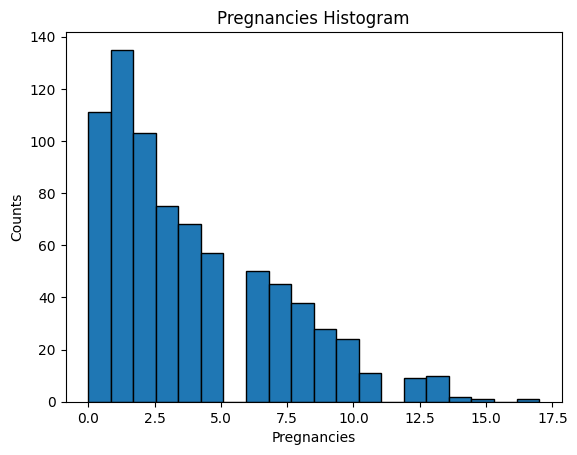

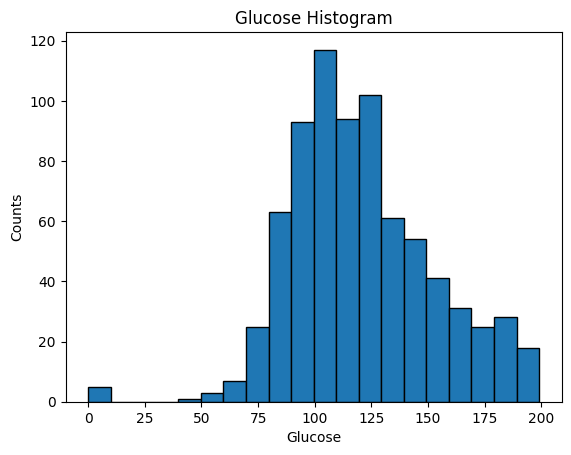

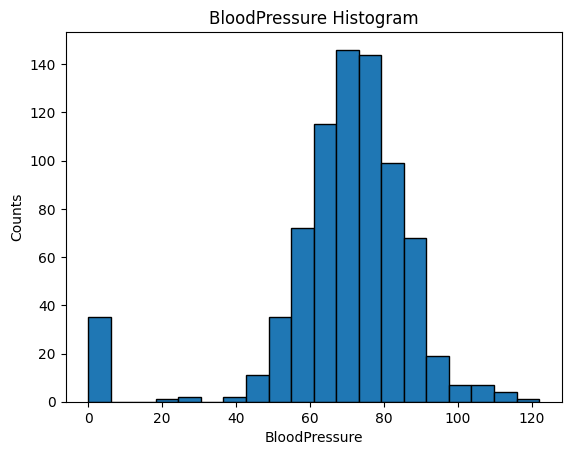

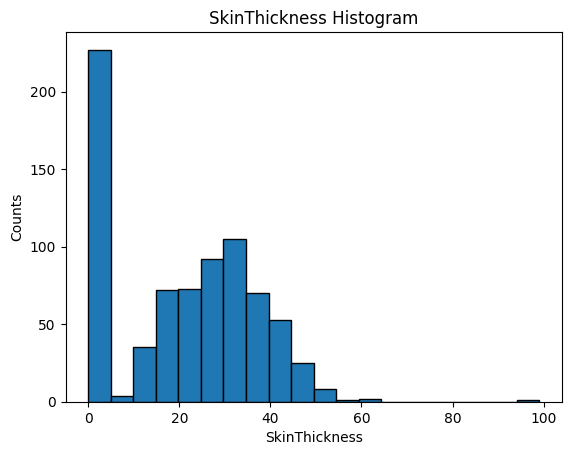

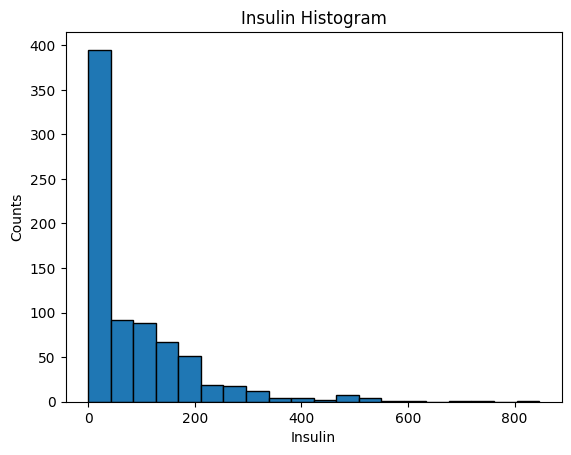

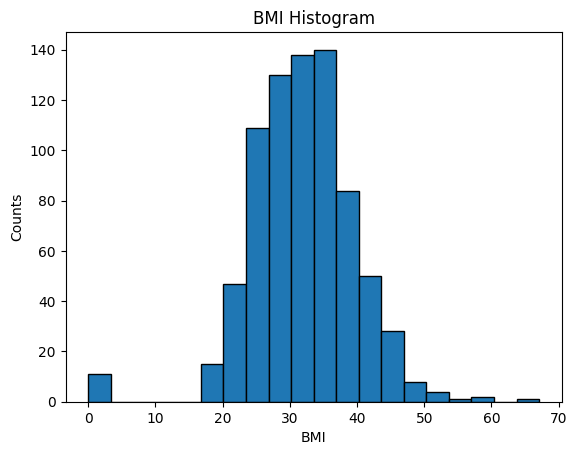

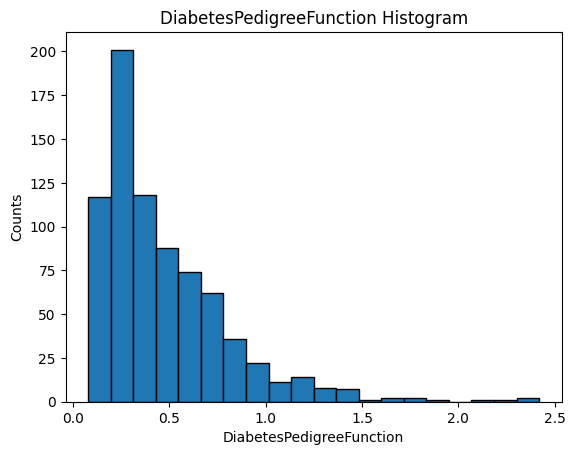

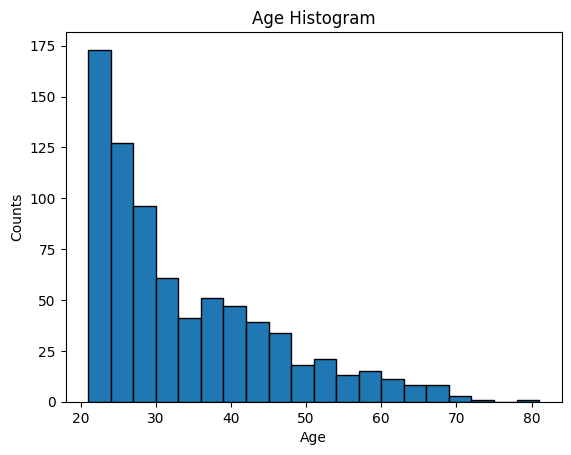

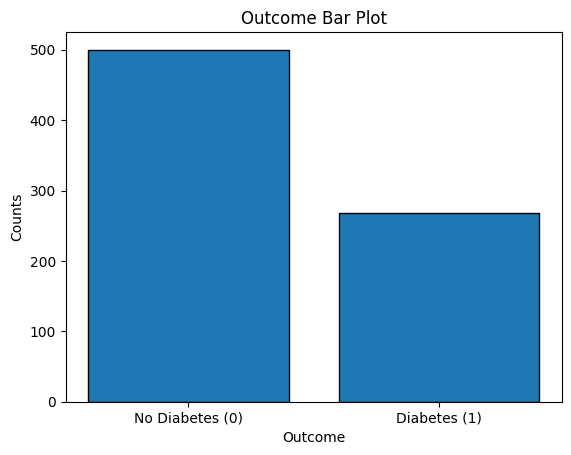

In [13]:
# Ιστογράμματα για όλα τα χαρακτηριστικά(μέση τιμή, τυπική απόκλιση, ελάχιστη και μέγιστη τιμή)
features = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']

for col in features:
    df[col].hist(bins=20, edgecolor='black')
    plt.title(f'{col} Histogram')
    plt.xlabel(col)
    plt.ylabel('Counts')
    plt.grid(False)
    plt.show()

# Ραβδόγραμμα (Bar Plot) για την μεταβλητή Outcome
outcome_counts = df['Outcome'].value_counts()
plt.bar(['No Diabetes (0)', 'Diabetes (1)'], outcome_counts, edgecolor='black')
plt.title('Outcome Bar Plot')
plt.xlabel('Outcome')
plt.ylabel('Counts')
plt.grid(False)
plt.show()

In [19]:
#Μέρος1_Ερώτημα2
___________________________________________________________________________________________________

#Δημιουργία Numpy arrays για inputs (x) και targets (y)
input_df = df.drop(columns=['Outcome'])
targets_df = df['Outcome']

x = input_df.to_numpy()
y = targets_df.to_numpy()

# 2. Χωρισμός σε σύνολα εκπαίδευσης
seed = 0
test_size = 0.3

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=test_size, random_state=seed)

# 3. Εμφάνιση του πλήθους των παραδειγμάτων
print(f'Πλήθος παραδειγμάτων εκπαίδευσης (Train set): {x_train.shape[0]}')
print(f'Πλήθος παραδειγμάτων επικύρωσης (Validation/Test set): {x_test.shape[0]}')


Πλήθος παραδειγμάτων εκπαίδευσης (Train set): 537
Πλήθος παραδειγμάτων επικύρωσης (Validation/Test set): 231


In [23]:
#Μέρος1_Ερώτημα3
_________________________________________________________________

#Δημιουργία και εκπαίδευση του μοντέλου Λογιστικής Παλινδρόμησης
model = LogisticRegression(max_iter=5000, random_state=0)
model.fit(x_train, y_train)


LogisticRegression(max_iter=5000, random_state=0)

In [25]:
#Υπολογισμός προβλέψεων για train και test sets
y_train_pred = model.predict(x_train)
y_test_pred = model.predict(x_test)

#Υπολογισμός και στρογγυλοποίηση
train_accuracy = accuracy_score(y_train, y_train_pred)
train_accuracy_percentage = round(train_accuracy * 100, 2)

test_accuracy = accuracy_score(y_test, y_test_pred)
test_accuracy_percentage = round(test_accuracy * 100, 2)

print(f'Train accuracy: {train_accuracy_percentage}')
print(f'Test accuracy: {test_accuracy_percentage}')

Train accuracy: 76.54
Test accuracy: 77.92


***Παρατήρηση:***

Η ακρίβεια στο σύνολο εκπαίδευσης(train set) είναι ελαφρώς υψηλότερη σε σύγκριση με την ακρίβεια στο σύνολο δοκιμων (test set). Η διαφορά αυτή είναι φυσιολογική βάση των δεδομένων μας. Η μικρή αυτή απόκλιση μας δείχνει ότι το μοντέλο μας δουλεύει καλά και γενικεύει σωστά και σε δεδομένα που δεν έχει ξαναδεί, οπότε δεν έχουμε κάποιο θέμα overfitting.

Outcome
0    109.980000
1    141.257463
Name: Glucose, dtype: float64


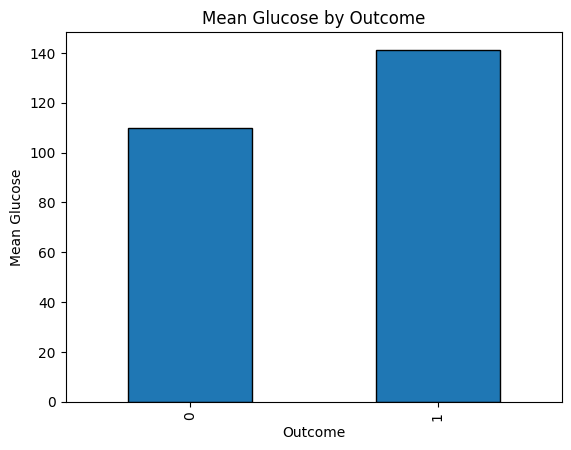

In [27]:
#Μέρος1_Ερώτημα4
__________________________________________________________________

# Υπολογισμός μέσης τιμής γλυκόζης ανάλογα με το Outcome
glucose_mean = df.groupby('Outcome')['Glucose'].mean()
print(glucose_mean)

#Ιστόγραμμα
glucose_mean.plot(kind='bar', edgecolor='black')
plt.title('Mean Glucose by Outcome')
plt.xlabel('Outcome')
plt.ylabel('Mean Glucose')
plt.grid(False)
plt.show()

***Παρατήρηση:***

Σύμφωνα με κλινικές μελέτες, αν κάποιος ασθενής έχει υψηλά επίπεδα γλυκόζης, είναι πολύ πιθανό να εμφανίσει διαβήτη.Αυτό ισχύει.Αν εξετάσουμε τα δεδομένα, οι ασθενείς που έχουν διαβήτη (outcome=1) εμφανίζουν σημαντικά υψηλότερη μέση τιμή γλυκόζης σε σύγκριση με όσους δεν έχουν (outcome=0). Αυτό επιβεβαιώνεται και από τη συνολική ανάλυση των συσχετίσεων, όπου η γλυκόζη παρατηρείται ως ένας από τους βασικότερους προγνωστικούς δείκτες για την εμφάνιση της νόσου αυτής.

Accuracy for Age 0-25: 85.56%
Accuracy for Age 25-50: 70.0%
Accuracy for Age >50: 90.48%


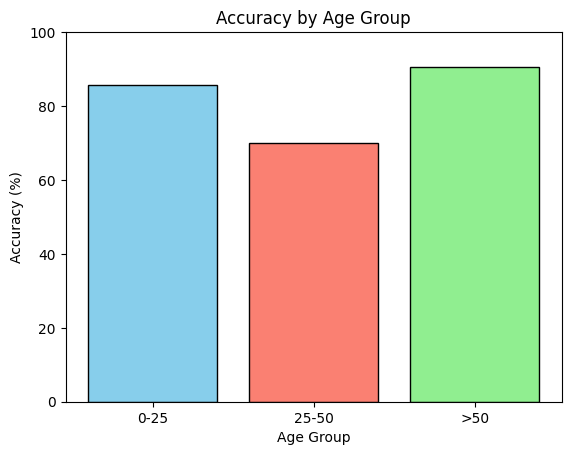

In [29]:
#Μέρος1_Ερώτημα5
______________________________________________________________________________

# Η στήλη 'Age' είναι η 7η στήλη
age_test = x_test[:, 7]

# Δημιουργία φίλτρων για κάθε ηλικιακή ομάδα
age_group_1 = age_test <= 25
age_group_2 = (age_test > 25) & (age_test <= 50)
age_group_3 = age_test > 50

#Υπολογισμός ακρίβειας για κάθε ομάδα
acc_group1 = accuracy_score(y_test[age_group_1], y_test_pred[age_group_1])
acc_group1_pct = round(acc_group1 * 100, 2)

acc_group2 = accuracy_score(y_test[age_group_2], y_test_pred[age_group_2])
acc_group2_pct = round(acc_group2 * 100, 2)

acc_group3 = accuracy_score(y_test[age_group_3], y_test_pred[age_group_3])
acc_group3_pct = round(acc_group3 * 100, 2)

print(f'Accuracy for Age 0-25: {acc_group1_pct}%')
print(f'Accuracy for Age 25-50: {acc_group2_pct}%')
print(f'Accuracy for Age >50: {acc_group3_pct}%')

#Δημιουργία ραβδογράμματος
age_groups = ['0-25', '25-50', '>50']
accuracies = [acc_group1_pct, acc_group2_pct, acc_group3_pct]

plt.bar(age_groups, accuracies, color=['skyblue', 'salmon', 'lightgreen'], edgecolor='black')
plt.title('Accuracy by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Accuracy (%)')
plt.ylim(0, 100)

plt.show()


***Παρατήρηση:***

Βλέπουμε οτι ο ταξινομητής δεν έχει την ίδια απόδοση σε όλες τις ηλικίες. Στην ομάδα 0-25 έχουμε ακρίβεια 85.56% και στην ομάδα >50 η ακρίβεια φτάνει το 90.48%. Αντίθετα, στη μεσαία ομάδα 25-50 η ακρίβεια πέφτει στο 70.0%. Αυτό συμβαίνει επειδή στις ενδιάμεσες ηλικίες τα δεδομένα των ασθενών με και χωρίς διαβήτη είναι πιο κοντά μεταξύ τους, με αποτέλεσμα το μοντέλο να κάνει περισσότερα λάθη στις προβλέψεις.

***Μέρος1_Ερώτημα6***
________________________________________________________________

Στη συγκεκριμένη ιατρική εφαρμογή, θεωρώ ότι είναι χειρότερο να προβλέψουμε ότι κάποιος ασθενής δεν έχει διαβήτη ενώ στην πραγματικότητα έχει.

Αν κάνουμε το λάθος να πούμε σε έναν υγιή άνθρωπο ότι έχει διαβήτη, η συνέπεια είναι κυρίως η ψυχολογική του ανησυχία και η ανάγκη για κάποιες επιπλέον επαναληπτικές εξετάσεις. Αν όμως αποτύχουμε να εντοπίσουμε έναν πραγματικό ασθενή , ο ασθενής αυτός μένει χωρίς διάγνωση και χωρίς καμία ιατρική παρακολούθηση ή θεραπεία, κάτι που μπορεί να έχει πολύ σοβαρές επιπτώσεις στην υγεία του. Στην ιατρική διάγνωση, η ασφάλεια του ασθενούς προϋποθέτει να ελαχιστοποιούμε τα ψευδώς αρνητικά αποτελέσματα.



---


***Μέρος 2 της εργασίας***

---



In [34]:
#Μέρος2_Ερώτημα1

#Φόρτωση του συνόλου δεδομένων
df = pd.read_csv('diabetes.csv')

#Ορισμός των inputs (x) και του target (y)
# Inputs: Pregnancies, BloodPressure, BMI, Age
input_df = df[feature_cols]
targets_df = df['Glucose']

x = input_df.to_numpy()
y = targets_df.to_numpy()

x.shape, y.shape

((768, 4), (768,))

In [36]:
#Διαχωρισμός δεδομένων

seed = 0
test_size = 0.3

x_train, x_val, y_train, y_val = train_test_split(x, y, test_size=test_size, random_state=seed)

x_train.shape, y_train.shape, x_val.shape, y_val.shape

((537, 4), (537,), (231, 4), (231,))

In [41]:
#Μέρος2_Ερώτημα2

# Δημιουργία και εκπαίδευση μοντέλου Γραμμικής Παλινδρόμησης
model = LinearRegression()
model.fit(x_train, y_train)

# Υπολογισμός του R^2 Score (ακρίβειας/προσαρμογής του μοντέλου)
r2 = model.score(x_val, y_val)
print(f'R^2 Score: {r2}')


R^2 Score: 0.0499622547687687


***Παρατήρηση:***

Με βάση τα αποτελέσματα μας, η Mean Absolute Error (MAE) είναι η καταλληλότερη μετρική διότι εκφράζεται στις ίδιες μονάδες με τη γλυκόζη (mg/dL), κάνοντας το σφάλμα άμεσα κατανοητό στην πράξη. Επιπλέον, επειδή τα ιατρικά δεδομένα συχνά περιέχουν ακραίες τιμές, η MAE είναι πιο ανθεκτική σε σχέση με τη Mean Squared Error (MSE), η οποία τετραγωνίζει τα σφάλματα και επηρεάζεται υπερβολικά από αυτά.

In [44]:
#Μέρος2_Ερώτημα3

# Εφαρμογή κανονικοποίησης (StandardScaler) στα inputs x
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)

# Διαχωρισμός των κανονικοποιημένων δεδομένων σε train και val (με ίδια seed=0)
x_train_scaled, x_val_scaled, y_train_scaled, y_val_scaled = train_test_split(x_scaled, y, test_size=test_size, random_state=seed)

# Εκπαίδευση νέου μοντέλου Γραμμικής Παλινδρόμησης με τα κανονικοποιημένα δεδομένα
model_scaled = LinearRegression()
model_scaled.fit(x_train_scaled, y_train_scaled)

# Εκτύπωση των συντελεστών για κάθε χαρακτηριστικό
for feature, coef in zip(feature_cols, model_scaled.coef_):
    print(f'{feature}: {coef}')


Pregnancies: -0.5663695132695087
BloodPressure: 0.7893929772480703
BMI: 7.422663926530703
Age: 9.030433824372988


***Παρατήρηση:***

Μετά την εφαρμογή της κανονικοποίησης (StandardScaler), όλα τα χαρακτηριστικά βρίσκονται πλέον στην ίδια κλίμακα, επιτρέποντας την απευθείας σύγκριση των συντελεστών τους.Η πιο σημαντική ανεξάρτητη μεταβλητή για την πρόβλεψη της γλυκόζης είναι η Ηλικία (Age), καθώς διαθέτει τη μεγαλύτερη απόλυτη τιμή συντελεστή ($\approx 9.03$), ακολουθούμενη στενά από τον δείκτη BMI ($\approx 7.42$). Αυτό σημαίνει ότι η ηλικία ασκεί τη μεγαλύτερη γραμμική επίδραση στην τιμή της γλυκόζης σε σχέση με τα υπόλοιπα χαρακτηριστικά.